In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns


def audit_raw_data(df):
    """
    Audits the raw dataset for duplicates, string formatting errors,
    out-of-range percentages, and missing values.
    """
    print(f"Initial Raw Dataset Shape: {df.shape}")
    print(f"Exact duplicate rows: {df.duplicated().sum()}")

    # Check whitespace issues in Country Name
    ws_names = df[df["Country Name"] != df["Country Name"].str.strip()]["Country Name"].tolist()
    print(f"Country Names with leading/trailing spaces ({len(ws_names)}): {ws_names}")

    # Check lowercase Country Codes
    bad_codes = df[~df["Country Code"].str.match(r"^[A-Z]{3}$")]["Country Code"].tolist()
    print(f"Lowercase Country Codes ({len(bad_codes)}): {bad_codes}")

    # Identify non-numeric strings in year columns
    year_cols = [col for col in df.columns if str(col).isdigit()]
    obj_cols = [col for col in year_cols if df[col].dtype == "object"]
    print(f"\nYear columns stored as object dtype: {obj_cols}")

    for col in obj_cols:
        for idx, val in df[col].dropna().items():
            try:
                float(val)
            except ValueError:
                print(f"  -> String error in {col} | {df.loc[idx, 'Country Name']}: '{val}'")


def clean_dataset(df, save_path="cleaned_agriculture_employment.csv"):
    """
    Cleans all structural, string, range, and missingness errors in the dataset
    and saves the sanitized dataframe to a CSV file.
    """
    cleaned = df.copy()

    # 1. Strip whitespace and standardize Country Code to uppercase
    cleaned["Country Name"] = cleaned["Country Name"].astype(str).str.strip()
    cleaned["Country Code"] = cleaned["Country Code"].astype(str).str.strip().str.upper()

    # 2. Fix spelling typos and inconsistent capitalization in Country Name
    name_fixes = {
        "Qatra": "Qatar",
        "Nciaragua": "Nicaragua",
        "BURKINA FASO": "Burkina Faso",
        "ERITREA": "Eritrea",
        "BANGLADESH": "Bangladesh",
        "afghanistan": "Afghanistan",
        "american samoa": "American Samoa",
        "isle of man": "Isle of Man"
    }
    cleaned["Country Name"] = cleaned["Country Name"].replace(name_fixes)

    # 3. Remove exact and near-duplicate rows (Seychelles, Malawi, Djibouti, etc.)
    cleaned = cleaned.drop_duplicates(subset=["Country Code"], keep="first").copy()

    # 4. Clean corrupted strings in year columns (~38.1, 61,6, 13.30%, etc.) and convert to float
    year_cols = [col for col in cleaned.columns if str(col).isdigit()]
    for col in year_cols:
        if cleaned[col].dtype == "object":
            s = cleaned[col].astype(str).str.replace(",", ".", regex=False)
            s = s.str.replace(r"(?i)percent|[~%!']", "", regex=True).str.strip()
            cleaned[col] = pd.to_numeric(s, errors="coerce")
        else:
            cleaned[col] = pd.to_numeric(cleaned[col], errors="coerce")

    # 5. Mask impossible percentage values (< 0% or > 100%) as NaN
    for col in year_cols:
        invalid_mask = (cleaned[col] < 0) | (cleaned[col] > 100)
        if invalid_mask.any():
            cleaned.loc[invalid_mask, col] = np.nan

    # 6. Drop 100% empty year columns (1960-1990) and 100% empty country rows
    empty_year_cols = [col for col in year_cols if cleaned[col].isnull().all()]
    cleaned.drop(columns=empty_year_cols, inplace=True)

    valid_years = [col for col in cleaned.columns if str(col).isdigit()]
    cleaned = cleaned.dropna(subset=valid_years, how="all").copy()

    # 7. Interpolate isolated missing values linearly across each country's timeline
    cleaned[valid_years] = (
        cleaned[valid_years]
        .interpolate(method="linear", axis=1)
        .bfill(axis=1)
        .ffill(axis=1)
    )

    print(f"\nCleaned Dataset Shape: {cleaned.shape} (234 entities x 39 columns)")
    print(f"Total remaining missing values: {cleaned.isnull().sum().sum()}")

    cleaned.to_csv(save_path, index=False)
    print(f"Saved cleaned dataset to '{save_path}'")
    return cleaned


# Run Phase 1
raw_df = pd.read_csv("1.Employment_Agriculture_Male_ASSIGNMENT_1_BB.csv")
audit_raw_data(raw_df)
cleaned_df = clean_dataset(raw_df)

Initial Raw Dataset Shape: (271, 70)
Exact duplicate rows: 3
Country Names with leading/trailing spaces (8): ['Peru   ', 'Sint Maarten (Dutch part)   ', '  Hungary', 'Seychelles ', '  United Arab Emirates', '  Bulgaria', 'Malawi ', 'Djibouti ']
Lowercase Country Codes (4): ['tha', 'hkg', 'gib', 'mus']

Year columns stored as object dtype: ['1991', '1996', '2001', '2008', '2013', '2016', '2018', '2019', '2021']
  -> String error in 1991 | Pakistan: '~38.1'
  -> String error in 1996 | Cyprus: 'unknown'
  -> String error in 2001 | Slovenia: 'n.a.'
  -> String error in 2008 | Bolivia: '29.8 percent'
  -> String error in 2013 | Libya: '13.30%'
  -> String error in 2016 | South Sudan: '61,6'
  -> String error in 2018 | Iceland: '--'
  -> String error in 2018 | Jordan: '4.31!'
  -> String error in 2019 | Israel: ''1.3'
  -> String error in 2021 | Belize: 'missing'

Cleaned Dataset Shape: (234, 39) (234 entities x 39 columns)
Total remaining missing values: 0
Saved cleaned dataset to 'cleaned_

In [ ]:
def run_eda_summary(data, start_year="1991", end_year="2025"):
    """
    Computes descriptive statistics and overall correlation between the start
    and end years of the cleaned dataset.
    """
    summary_df = pd.DataFrame({
        f"{start_year} Stats": data[start_year].describe(),
        f"{end_year} Stats": data[end_year].describe()
    }).round(2)

    # Use built-in round() for scalar float values
    summary_df.loc["median"] = [
        round(data[start_year].median(), 2),
        round(data[end_year].median(), 2)
    ]

    iqr_start = data[start_year].quantile(0.75) - data[start_year].quantile(0.25)
    iqr_end = data[end_year].quantile(0.75) - data[end_year].quantile(0.25)
    summary_df.loc["IQR"] = [round(iqr_start, 2), round(iqr_end, 2)]

    corr_val = round(data[start_year].corr(data[end_year]), 3)

    print(f"--- Descriptive Statistics ({start_year} vs {end_year}) ---")
    print(summary_df)
    print(f"\nLong-term Pearson Correlation ({start_year} vs {end_year}): r = {corr_val}")
    return summary_df


# Run Phase 2
eda_stats = run_eda_summary(cleaned_df)

--- Descriptive Statistics (1991 vs 2025) ---
        1991 Stats  2025 Stats
count       234.00      234.00
mean         34.89       23.27
std          22.86       19.03
min           0.37        0.11
25%          13.92        5.92
50%          33.47       18.85
75%          53.30       35.31
max          88.24       77.01
median       33.47       18.85
IQR          39.37       29.40

Long-term Pearson Correlation (1991 vs 2025): r = 0.906


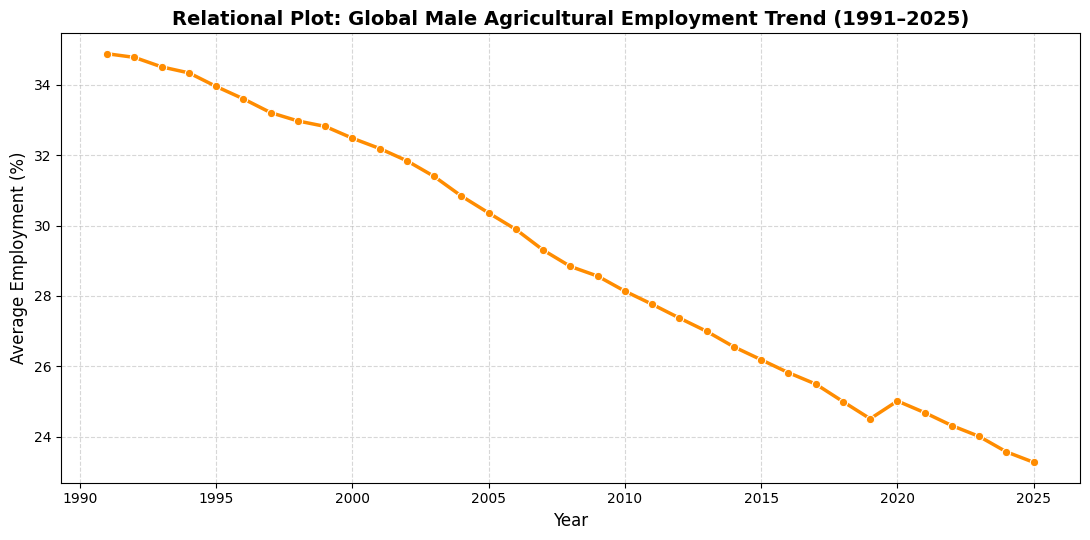

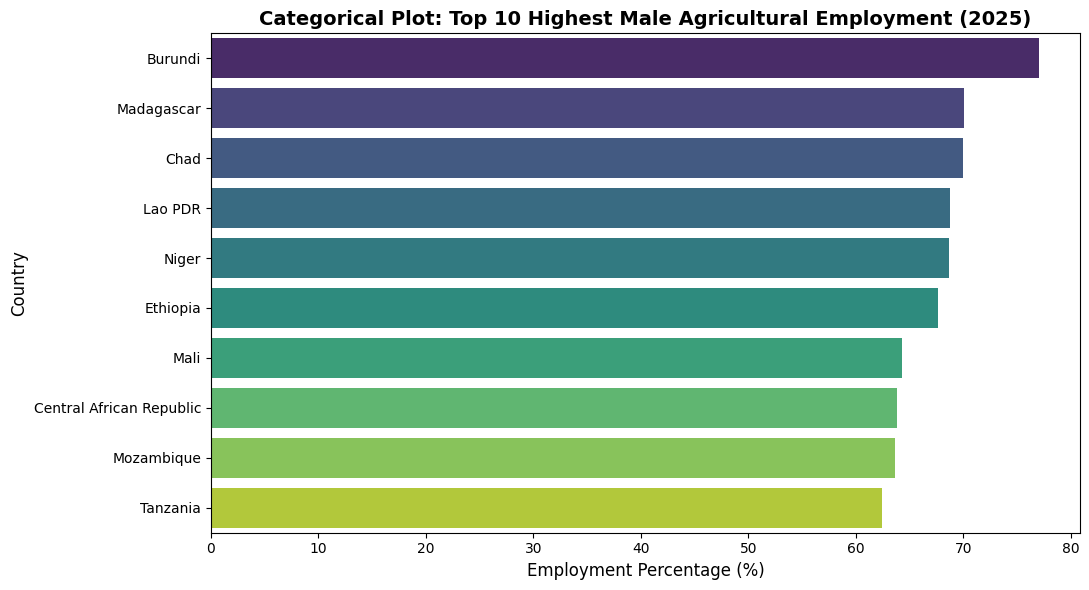

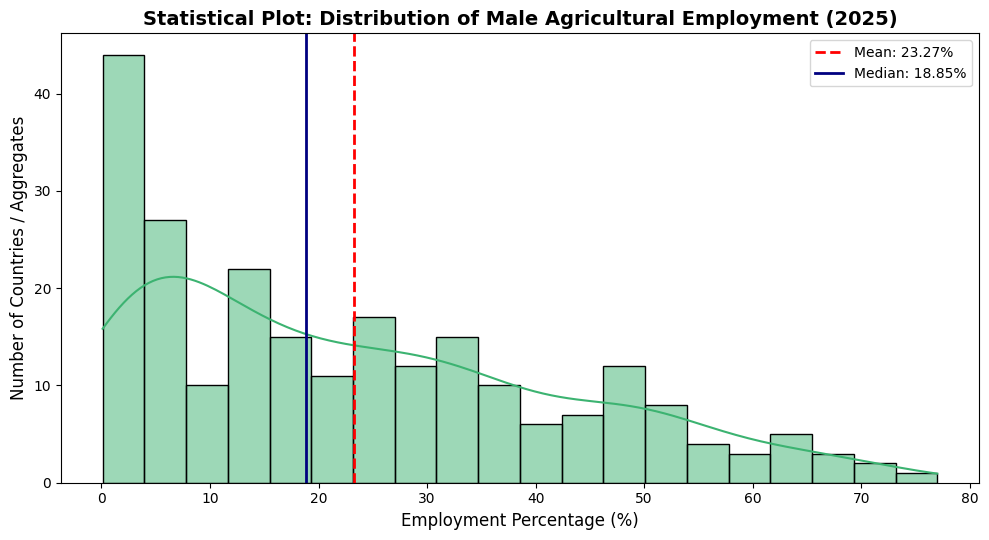

In [ ]:
# 1. RELATIONAL PLOT FUNCTION
def plot_global_employment_trend(data):
    """
    Relational Plot: Visualizes the global average trend of male agricultural
    employment from 1991 to 2025.
    """
    years = [col for col in data.columns if str(col).isdigit()]
    yearly_avg = data[years].mean()

    plt.figure(figsize=(11, 5.5))
    sns.lineplot(
        x=yearly_avg.index.astype(int),
        y=yearly_avg.values,
        color="darkorange",
        linewidth=2.5,
        marker="o"
    )
    plt.title("Relational Plot: Global Male Agricultural Employment Trend (1991–2025)", fontsize=14, fontweight="bold")
    plt.xlabel("Year", fontsize=12)
    plt.ylabel("Average Employment (%)", fontsize=12)
    plt.grid(True, linestyle="--", alpha=0.5)
    plt.tight_layout()
    plt.show()


# 2. CATEGORICAL PLOT FUNCTION
def plot_top_10_countries(data, year=2025):
    """
    Categorical Plot: Displays the Top 10 countries with the highest male
    agricultural employment in the specified year.
    """
    year_str = str(year)
    top_10 = data[["Country Name", year_str]].sort_values(by=year_str, ascending=False).head(10)

    plt.figure(figsize=(11, 6))
    sns.barplot(
        data=top_10,
        x=year_str,
        y="Country Name",
        hue="Country Name",
        palette="viridis",
        legend=False
    )
    plt.title(f"Categorical Plot: Top 10 Highest Male Agricultural Employment ({year_str})", fontsize=14, fontweight="bold")
    plt.xlabel("Employment Percentage (%)", fontsize=12)
    plt.ylabel("Country", fontsize=12)
    plt.tight_layout()
    plt.show()


# 3. STATISTICAL PLOT FUNCTION
def plot_employment_distribution(data, year=2025):
    """
    Statistical Plot: Displays the distribution (Histogram + KDE) and central
    tendency (Mean vs. Median) of male agricultural employment.
    """
    year_str = str(year)
    values = data[year_str]

    plt.figure(figsize=(10, 5.5))
    sns.histplot(values, bins=20, kde=True, color="mediumseagreen", edgecolor="black")

    # Add Mean and Median reference lines for statistical depth
    plt.axvline(values.mean(), color="red", linestyle="--", linewidth=2, label=f"Mean: {values.mean():.2f}%")
    plt.axvline(values.median(), color="navy", linestyle="-", linewidth=2, label=f"Median: {values.median():.2f}%")

    plt.title(f"Statistical Plot: Distribution of Male Agricultural Employment ({year_str})", fontsize=14, fontweight="bold")
    plt.xlabel("Employment Percentage (%)", fontsize=12)
    plt.ylabel("Number of Countries / Aggregates", fontsize=12)
    plt.legend()
    plt.tight_layout()
    plt.show()


# Generate the 3 Core Visualizations from cleaned_df
plot_global_employment_trend(cleaned_df)
plot_top_10_countries(cleaned_df, year=2025)
plot_employment_distribution(cleaned_df, year=2025)